# VOiCES Voice Activity Detection (VAD)

**Third assignment task — standalone notebook**

This notebook applies a pretrained **Silero Voice Activity Detection (VAD)** model to a stratified 10% sample of the Lab41 VOiCES subset.

### What this notebook does
1. Installs dependencies and mounts Google Drive.
2. Downloads the eight VOiCES archive files directly from the Lab41 GitHub repository.
3. Indexes recordings and selects a stratified 10% sample across `none`, `babb`, `tele`, and `musi`.
4. Extracts only the selected WAV recordings.
5. Runs Silero VAD and records speech-active intervals.
6. Calculates speech-duration statistics and saves CSV files and figures to Google Drive.

**Methodological note:** This is pretrained-model VAD inference, not supervised VAD training. The Lab41 subset does not provide frame-level speech/non-speech reference timestamps, so precision, recall, and F1 cannot be calculated reliably from this dataset. The distractor labels describe recording conditions; they are not VAD ground-truth labels.


## 1. Install dependencies

In [1]:
!pip -q install numpy pandas soundfile matplotlib tqdm scikit-learn silero-vad requests

## 2. Imports, Drive setup, and configuration

In [2]:
from pathlib import Path
import os
import re
import tarfile
import random
import requests
import numpy as np
import pandas as pd
import soundfile as sf
import matplotlib.pyplot as plt
from tqdm.auto import tqdm
from sklearn.model_selection import train_test_split

from google.colab import drive
drive.mount('/content/drive')

import torch
from silero_vad import load_silero_vad, read_audio, get_speech_timestamps

# Reproducibility
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

# Dataset and experiment configuration
REPO_RAW_URL = "https://raw.githubusercontent.com/Lab41/VOiCES-subset/master"
ARCHIVE_IDS = range(1, 9)
SAMPLE_FRACTION = 0.10
TARGET_SR = 16000

# All work is self-contained in this notebook's runtime.
WORK_DIR = Path("/content/voices_vad_project")
ARCHIVE_DIR = WORK_DIR / "archives"
AUDIO_DIR = WORK_DIR / "selected_audio"

# Persistent results in Google Drive
OUT_DIR = Path("/content/drive/MyDrive/VOiCES_VAD_Project")
TABLE_DIR = OUT_DIR / "tables"
FIGURE_DIR = OUT_DIR / "figures"
MODEL_DIR = OUT_DIR / "models"

for folder in [ARCHIVE_DIR, AUDIO_DIR, TABLE_DIR, FIGURE_DIR, MODEL_DIR]:
    folder.mkdir(parents=True, exist_ok=True)

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

print("Device:", DEVICE)
print("Target sample rate:", TARGET_SR)
print("Sample fraction:", SAMPLE_FRACTION)
print("Output directory:", OUT_DIR)


Mounted at /content/drive
Device: cuda
Target sample rate: 16000
Sample fraction: 0.1
Output directory: /content/drive/MyDrive/VOiCES_VAD_Project


## 3. Download the VOiCES archives from GitHub

The source files are gzip-compressed TAR archives even though their names end in `.tar`. The code uses `tarfile` mode `r:*` so the compression is detected automatically.

In [3]:
def download_archive(archive_id):
    filename = f"VOiCES_90_{archive_id}.tar"
    url = f"{REPO_RAW_URL}/{filename}"
    destination = ARCHIVE_DIR / filename

    if destination.exists() and destination.stat().st_size > 0:
        return destination

    print(f"Downloading {filename} ...")
    response = requests.get(url, stream=True, timeout=120)
    response.raise_for_status()

    temp_path = destination.with_suffix(destination.suffix + ".part")
    with open(temp_path, "wb") as f:
        for chunk in response.iter_content(chunk_size=1024 * 1024):
            if chunk:
                f.write(chunk)

    temp_path.replace(destination)
    return destination

archive_paths = []
for archive_id in ARCHIVE_IDS:
    archive_paths.append(download_archive(archive_id))

print("\nDownloaded/available archives:")
for path in archive_paths:
    print(path.name, f"{path.stat().st_size / (1024**3):.2f} GB")



Downloaded/available archives:
VOiCES_90_1.tar 0.04 GB
VOiCES_90_2.tar 0.04 GB
VOiCES_90_3.tar 0.04 GB
VOiCES_90_4.tar 0.04 GB
VOiCES_90_5.tar 0.04 GB
VOiCES_90_6.tar 0.04 GB
VOiCES_90_7.tar 0.04 GB
VOiCES_90_8.tar 0.05 GB


## 4. Index the WAV recordings and identify distractor conditions

The filename pattern identifies the recording condition. The labels are `none`, `babb` (babble), `tele` (television), and `musi` (music).

In [4]:
filename_pattern = re.compile(
    r"Lab41-SRI-VOiCES-rm\d+-(none|babb|tele|musi)-sp\d+-ch\d+-sg\d+-mc\d+-stu-[a-z]+-dg\d+\.wav$",
    re.IGNORECASE
)

manifest = []

for archive_path in archive_paths:
    print("Indexing:", archive_path.name)
    with tarfile.open(archive_path, mode="r:*") as tar:
        for member in tar:
            if not member.isfile() or not member.name.lower().endswith(".wav"):
                continue

            basename = Path(member.name).name
            match = filename_pattern.search(basename)
            if match:
                manifest.append({
                    "archive": str(archive_path),
                    "member": member.name,
                    "filename": basename,
                    "label": match.group(1).lower()
                })

manifest_df = pd.DataFrame(manifest)

if manifest_df.empty:
    raise RuntimeError(
        "No matching VOiCES WAV files were found. Check the repository download and filename pattern."
    )

manifest_df = manifest_df.drop_duplicates(subset=["archive", "member"]).reset_index(drop=True)

print("Total indexed recordings:", len(manifest_df))
display(manifest_df["label"].value_counts().rename_axis("condition").to_frame("recordings"))


Indexing: VOiCES_90_1.tar
Indexing: VOiCES_90_2.tar
Indexing: VOiCES_90_3.tar
Indexing: VOiCES_90_4.tar
Indexing: VOiCES_90_5.tar
Indexing: VOiCES_90_6.tar
Indexing: VOiCES_90_7.tar
Indexing: VOiCES_90_8.tar
Total indexed recordings: 909


,recordings
condition,
musi,231
babb,228
none,227
tele,223


## 5. Select a stratified 10% sample

In [5]:
if len(manifest_df) < 20:
    raise RuntimeError(f"Only {len(manifest_df)} recordings were indexed; this is too few for the planned sample.")

sample_count = max(1, int(round(len(manifest_df) * SAMPLE_FRACTION)))

# Stratify by distractor condition so the sample retains the class distribution.
selected_df, _ = train_test_split(
    manifest_df,
    train_size=sample_count,
    random_state=SEED,
    stratify=manifest_df["label"]
)

selected_df = selected_df.reset_index(drop=True)

print("Total recordings:", len(manifest_df))
print("Selected recordings:", len(selected_df))
print("Actual sample fraction:", round(len(selected_df) / len(manifest_df), 4))
display(selected_df["label"].value_counts().sort_index().rename_axis("condition").to_frame("selected_recordings"))


Total recordings: 909
Selected recordings: 91
Actual sample fraction: 0.1001


,selected_recordings
condition,
babb,23
musi,23
none,23
tele,22


## 6. Extract only the selected WAV files

In [6]:
selected_keys = {}
for row in selected_df.itertuples(index=False):
    selected_keys.setdefault(row.archive, set()).add(row.member)

extracted_paths = {}

for archive_path in archive_paths:
    archive_key = str(archive_path)
    wanted_members = selected_keys.get(archive_key, set())

    if not wanted_members:
        continue

    print(f"Extracting {len(wanted_members)} selected files from {archive_path.name}")

    with tarfile.open(archive_path, mode="r:*") as tar:
        for member in tar:
            if member.name not in wanted_members or not member.isfile():
                continue

            source = tar.extractfile(member)
            if source is None:
                continue

            output_name = f"{len(extracted_paths):05d}_{Path(member.name).name}"
            output_path = AUDIO_DIR / output_name

            with source, open(output_path, "wb") as destination:
                destination.write(source.read())

            extracted_paths[(archive_key, member.name)] = str(output_path)

selected_df["audio_path"] = [
    extracted_paths.get((row.archive, row.member))
    for row in selected_df.itertuples(index=False)
]
selected_df = selected_df.dropna(subset=["audio_path"]).reset_index(drop=True)

print("Successfully extracted:", len(selected_df))
if len(selected_df) < 1:
    raise RuntimeError("No selected WAV files were extracted.")

display(selected_df[["filename", "label", "audio_path"]].head())


Extracting 10 selected files from VOiCES_90_1.tar
Extracting 13 selected files from VOiCES_90_2.tar
Extracting 13 selected files from VOiCES_90_3.tar
Extracting 11 selected files from VOiCES_90_4.tar
Extracting 4 selected files from VOiCES_90_5.tar
Extracting 10 selected files from VOiCES_90_6.tar
Extracting 13 selected files from VOiCES_90_7.tar
Extracting 17 selected files from VOiCES_90_8.tar
Successfully extracted: 91


,filename,label,audio_path
0,Lab41-SRI-VOiCES-rm2-babb-sp1272-ch135031-sg00...,babb,/content/voices_vad_project/selected_audio/000...
1,Lab41-SRI-VOiCES-rm2-babb-sp3923-ch174992-sg00...,babb,/content/voices_vad_project/selected_audio/000...
2,Lab41-SRI-VOiCES-rm1-musi-sp7517-ch100442-sg00...,musi,/content/voices_vad_project/selected_audio/000...
3,Lab41-SRI-VOiCES-rm2-tele-sp6895-ch092806-sg00...,tele,/content/voices_vad_project/selected_audio/000...
4,Lab41-SRI-VOiCES-rm2-none-sp0948-ch132705-sg00...,none,/content/voices_vad_project/selected_audio/000...


## 7. Validate the extracted audio

In [7]:
audio_checks = []

for row in tqdm(selected_df.itertuples(index=False), total=len(selected_df)):
    try:
        info = sf.info(row.audio_path)
        audio_checks.append({
            "filename": row.filename,
            "label": row.label,
            "sample_rate": info.samplerate,
            "channels": info.channels,
            "duration_seconds": info.duration,
            "readable": True
        })
    except Exception as exc:
        audio_checks.append({
            "filename": row.filename,
            "label": row.label,
            "sample_rate": None,
            "channels": None,
            "duration_seconds": None,
            "readable": False,
            "error": str(exc)
        })

audio_check_df = pd.DataFrame(audio_checks)
display(audio_check_df.head())
print("Readable files:", int(audio_check_df["readable"].sum()), "/", len(audio_check_df))

valid_names = set(audio_check_df.loc[audio_check_df["readable"], "filename"])
selected_df = selected_df[selected_df["filename"].isin(valid_names)].reset_index(drop=True)

if selected_df.empty:
    raise RuntimeError("No readable WAV recordings remain after validation.")


  0%|          | 0/91 [00:00<?, ?it/s]

,filename,label,sample_rate,channels,duration_seconds,readable
0,Lab41-SRI-VOiCES-rm2-babb-sp1272-ch135031-sg00...,babb,16000,1,10.885,True
1,Lab41-SRI-VOiCES-rm2-babb-sp3923-ch174992-sg00...,babb,16000,1,15.620,True
2,Lab41-SRI-VOiCES-rm1-musi-sp7517-ch100442-sg00...,musi,16000,1,16.385,True
3,Lab41-SRI-VOiCES-rm2-tele-sp6895-ch092806-sg00...,tele,16000,1,16.060,True
4,Lab41-SRI-VOiCES-rm2-none-sp0948-ch132705-sg00...,none,16000,1,16.640,True


Readable files: 91 / 91


## 8. Load the pretrained Silero VAD model

In [8]:
vad_model = load_silero_vad(onnx=False)
vad_model.eval()
print("Silero VAD model loaded successfully.")
print("VAD inference will run on:", DEVICE)


/usr/local/lib/python3.13/dist-packages/torch/jit/_serialization.py:176: FutureWarning: `torch.jit.load` is deprecated. Please switch to `torch.export`.
  warnings.warn(


Silero VAD model loaded successfully.
VAD inference will run on: cuda


## 9. Run VAD and collect speech-active intervals

The model returns time intervals that it detects as speech. The `threshold`, minimum speech duration, and minimum silence duration are explicit experiment settings.

In [9]:
VAD_THRESHOLD = 0.5
MIN_SPEECH_DURATION_MS = 250
MIN_SILENCE_DURATION_MS = 100

recording_records = []
interval_records = []

for row in tqdm(selected_df.itertuples(index=False), total=len(selected_df)):
    try:
        # Silero's helper loads the file as mono audio at the requested sample rate.
        audio = read_audio(row.audio_path, sampling_rate=TARGET_SR)
        duration = len(audio) / TARGET_SR

        timestamps = get_speech_timestamps(
            audio,
            vad_model,
            sampling_rate=TARGET_SR,
            threshold=VAD_THRESHOLD,
            min_speech_duration_ms=MIN_SPEECH_DURATION_MS,
            min_silence_duration_ms=MIN_SILENCE_DURATION_MS,
            return_seconds=True
        )

        speech_seconds = sum(
            max(0.0, float(segment["end"]) - float(segment["start"]))
            for segment in timestamps
        )
        speech_seconds = min(speech_seconds, duration)
        non_speech_seconds = max(0.0, duration - speech_seconds)
        speech_ratio = speech_seconds / duration if duration > 0 else 0.0

        recording_records.append({
            "audio_file": Path(row.audio_path).name,
            "original_filename": row.filename,
            "distractor_condition": row.label,
            "duration_seconds": duration,
            "detected_speech_seconds": speech_seconds,
            "estimated_non_speech_seconds": non_speech_seconds,
            "speech_ratio": speech_ratio,
            "number_of_speech_segments": len(timestamps)
        })

        for segment_number, segment in enumerate(timestamps, start=1):
            start_time = float(segment["start"])
            end_time = float(segment["end"])
            interval_records.append({
                "audio_file": Path(row.audio_path).name,
                "segment_id": segment_number,
                "start_seconds": start_time,
                "end_seconds": end_time,
                "duration_seconds": max(0.0, end_time - start_time),
                "distractor_condition": row.label
            })

    except Exception as exc:
        print(f"VAD failed for {row.audio_path}: {exc}")

summary_df = pd.DataFrame(recording_records)
intervals_df = pd.DataFrame(interval_records)

if summary_df.empty:
    raise RuntimeError("VAD did not successfully process any recordings.")

print("Successfully processed recordings:", len(summary_df))
print("Total detected speech segments:", len(intervals_df))
display(summary_df.head())


  0%|          | 0/91 [00:00<?, ?it/s]

Successfully processed recordings: 91
Total detected speech segments: 403


,audio_file,original_filename,distractor_condition,duration_seconds,detected_speech_seconds,estimated_non_speech_seconds,speech_ratio,number_of_speech_segments
0,00013_Lab41-SRI-VOiCES-rm2-babb-sp1272-ch13503...,Lab41-SRI-VOiCES-rm2-babb-sp1272-ch135031-sg00...,babb,10.885,9.80,1.085,0.900322,2
1,00012_Lab41-SRI-VOiCES-rm2-babb-sp3923-ch17499...,Lab41-SRI-VOiCES-rm2-babb-sp3923-ch174992-sg00...,babb,15.620,13.30,2.320,0.851472,5
2,00039_Lab41-SRI-VOiCES-rm1-musi-sp7517-ch10044...,Lab41-SRI-VOiCES-rm1-musi-sp7517-ch100442-sg00...,musi,16.385,12.60,3.785,0.768996,7
3,00043_Lab41-SRI-VOiCES-rm2-tele-sp6895-ch09280...,Lab41-SRI-VOiCES-rm2-tele-sp6895-ch092806-sg00...,tele,16.060,14.36,1.700,0.894147,4
4,00038_Lab41-SRI-VOiCES-rm2-none-sp0948-ch13270...,Lab41-SRI-VOiCES-rm2-none-sp0948-ch132705-sg00...,none,16.640,12.50,4.140,0.751202,6


## 10. Summarize VAD results by recording condition

In [10]:
overall_summary = pd.DataFrame([{
    "recordings_processed": len(summary_df),
    "total_audio_duration_seconds": summary_df["duration_seconds"].sum(),
    "total_detected_speech_seconds": summary_df["detected_speech_seconds"].sum(),
    "total_estimated_non_speech_seconds": summary_df["estimated_non_speech_seconds"].sum(),
    "mean_speech_ratio": summary_df["speech_ratio"].mean(),
    "median_speech_ratio": summary_df["speech_ratio"].median(),
    "mean_segments_per_recording": summary_df["number_of_speech_segments"].mean(),
    "total_detected_segments": len(intervals_df)
}])

condition_summary = (
    summary_df.groupby("distractor_condition")
    .agg(
        recordings=("audio_file", "count"),
        mean_duration_seconds=("duration_seconds", "mean"),
        mean_speech_seconds=("detected_speech_seconds", "mean"),
        mean_non_speech_seconds=("estimated_non_speech_seconds", "mean"),
        mean_speech_ratio=("speech_ratio", "mean"),
        mean_segments=("number_of_speech_segments", "mean")
    )
    .reset_index()
)

print("Overall summary")
display(overall_summary.round(4))
print("Summary by distractor condition")
display(condition_summary.round(4))


Overall summary


,recordings_processed,total_audio_duration_seconds,total_detected_speech_seconds,total_estimated_non_speech_seconds,mean_speech_ratio,median_speech_ratio,mean_segments_per_recording,total_detected_segments
0,91,1397.5899,1209.105,188.4849,0.8624,0.8786,4.4286,403


Summary by distractor condition


,distractor_condition,recordings,mean_duration_seconds,mean_speech_seconds,mean_non_speech_seconds,mean_speech_ratio,mean_segments
0,babb,23,14.7793,12.8526,1.9267,0.8623,3.9130
1,musi,23,15.1907,13.4130,1.7776,0.8771,4.3043
2,none,23,15.4789,13.0463,2.4326,0.8436,4.6522
3,tele,22,16.0120,13.8605,2.1516,0.8667,4.8636


## 11. Visualize the speech-ratio distribution

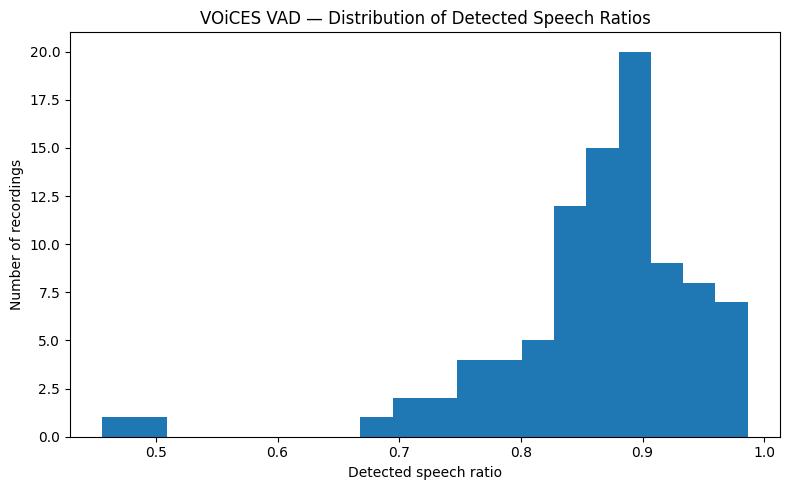

<Figure size 800x500 with 0 Axes>

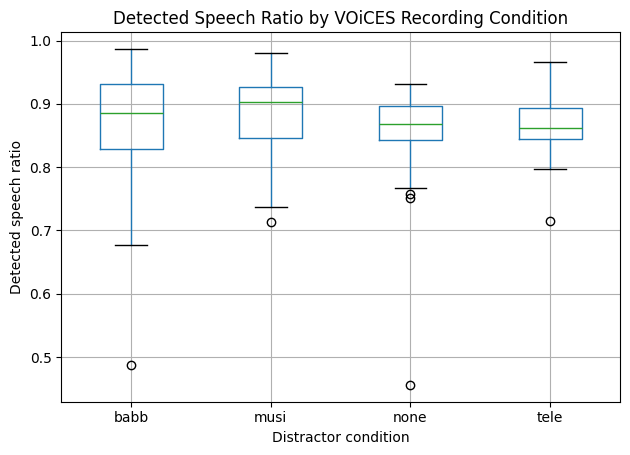

In [11]:
plt.figure(figsize=(8, 5))
plt.hist(summary_df["speech_ratio"], bins=20)
plt.xlabel("Detected speech ratio")
plt.ylabel("Number of recordings")
plt.title("VOiCES VAD — Distribution of Detected Speech Ratios")
plt.tight_layout()
plt.savefig(FIGURE_DIR / "speech_ratio_distribution.png", dpi=180)
plt.show()

plt.figure(figsize=(8, 5))
summary_df.boxplot(column="speech_ratio", by="distractor_condition")
plt.xlabel("Distractor condition")
plt.ylabel("Detected speech ratio")
plt.title("Detected Speech Ratio by VOiCES Recording Condition")
plt.suptitle("")
plt.tight_layout()
plt.savefig(FIGURE_DIR / "speech_ratio_by_condition.png", dpi=180)
plt.show()


## 12. Visualize one recording's speech timeline

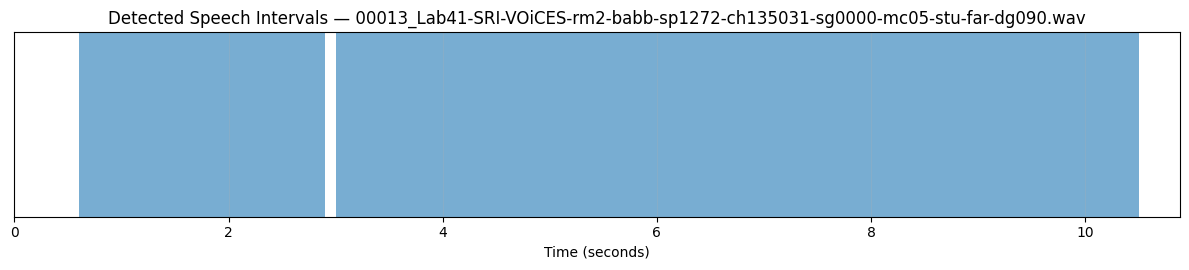

In [12]:
if not intervals_df.empty:
    example_file = intervals_df.iloc[0]["audio_file"]
    example_intervals = intervals_df[intervals_df["audio_file"] == example_file]
    example_summary = summary_df[summary_df["audio_file"] == example_file].iloc[0]

    fig, ax = plt.subplots(figsize=(12, 2.8))
    for _, segment in example_intervals.iterrows():
        ax.axvspan(segment["start_seconds"], segment["end_seconds"], alpha=0.6)

    ax.set_xlim(0, float(example_summary["duration_seconds"]))
    ax.set_ylim(0, 1)
    ax.set_yticks([])
    ax.set_xlabel("Time (seconds)")
    ax.set_title("Detected Speech Intervals — " + example_file)
    ax.grid(axis="x", alpha=0.25)
    plt.tight_layout()
    plt.savefig(FIGURE_DIR / "example_vad_timeline.png", dpi=180)
    plt.show()
else:
    print("No speech segments were detected in the processed sample.")


## 13. Save CSV results and figures to Google Drive

In [13]:
summary_csv = TABLE_DIR / "vad_recording_summary.csv"
intervals_csv = TABLE_DIR / "vad_speech_intervals.csv"
condition_csv = TABLE_DIR / "vad_condition_summary.csv"
overall_csv = TABLE_DIR / "vad_overall_summary.csv"
sample_csv = TABLE_DIR / "vad_selected_sample_manifest.csv"

summary_df.to_csv(summary_csv, index=False)
intervals_df.to_csv(intervals_csv, index=False)
condition_summary.to_csv(condition_csv, index=False)
overall_summary.to_csv(overall_csv, index=False)
selected_df.to_csv(sample_csv, index=False)

print("Saved files:")
for path in [summary_csv, intervals_csv, condition_csv, overall_csv, sample_csv]:
    print(path)
print("Figures directory:", FIGURE_DIR)


Saved files:
/content/drive/MyDrive/VOiCES_VAD_Project/tables/vad_recording_summary.csv
/content/drive/MyDrive/VOiCES_VAD_Project/tables/vad_speech_intervals.csv
/content/drive/MyDrive/VOiCES_VAD_Project/tables/vad_condition_summary.csv
/content/drive/MyDrive/VOiCES_VAD_Project/tables/vad_overall_summary.csv
/content/drive/MyDrive/VOiCES_VAD_Project/tables/vad_selected_sample_manifest.csv
Figures directory: /content/drive/MyDrive/VOiCES_VAD_Project/figures
